# C10 · Tọa độ song song của các đối tác thương mại

- **Task** · So sánh cơ cấu thương mại theo phần HS và tăng trưởng của các đối tác trong T18.
- **Dạng** · Mỗi đối tác là một đường đi qua bốn trục tỷ trọng HS và một trục CAGR. Bản nháp dùng đường xám và nhấn Trung Quốc (CHN), Hoa Kỳ (USA), Hàn Quốc (KOR) theo màu đối tác của House Style.
- **Lý do** · Bốn phần có tỷ trọng bình quân lớn nhất trong tập T18 giúp giữ số trục vừa phải. Trục cơ cấu đặt liền nhau, CAGR đặt cuối. Trong bốn trục cơ cấu, chọn thứ tự có ít giao cắt nhất giữa các trục kề nhau, tính cả đoạn nối đến CAGR.
- **Xử lý** · Dùng trực tiếp z-score do T18 xuất bằng StandardScaler. Mọi trục dùng cùng thang. Điểm 0 là trung bình của 39 đối tác, còn +1 là cao hơn trung bình một độ lệch chuẩn. Tỷ trọng tính từ tổng thương mại năm 2024, CAGR từ tổng thương mại 2015–2024.
- **T20 và M6** · Chạy được bản nháp khi nhãn cụm chưa có. Bản cụm ghép một–một theo `partner_code` và dùng đúng mã màu từ M6. Màu đối tác trên bản nháp và màu cụm trên bản T20 mang hai ý nghĩa riêng.

**Nguồn** · `data/clean/partner_features.csv`, `partner_features_standardized.csv` và `partner_feature_columns.csv` do T18 xuất.

In [1]:
import re
import sys
from itertools import combinations, permutations
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "notebooks" / "house_style" / "house_style.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from notebooks.house_style.house_style import (
    CONTEXT_COLOR, HS_LABELS, PARTNER_COLORS, PARTNER_LABELS, SOURCE, SUBTITLE,
    apply_style, format_number,
)

IDENTITY = ["partner_code", "partner_iso3", "partner_name"]
GROWTH = "cagr_pct"


def crossings(left, right):
    """Count strict pair reversals; ties do not count as crossings."""
    return sum((left[i] - left[j]) * (right[i] - right[j]) < 0
               for i, j in combinations(range(len(left)), 2))


def load_parallel(clean, count):
    raw = pd.read_csv(clean / "partner_features.csv", dtype={"partner_code": "string"})
    z = pd.read_csv(clean / "partner_features_standardized.csv", dtype={"partner_code": "string"})
    manifest = pd.read_csv(clean / "partner_feature_columns.csv").sort_values("feature_order")
    features = manifest["feature"].tolist()
    if (manifest["feature_order"].tolist() != list(range(1, len(features) + 1))
            or len(features) != len(set(features)) or list(z.columns) != IDENTITY + features):
        raise ValueError("Danh mục đặc trưng không khớp bảng z-score của T18.")
    for frame in (raw, z):
        if frame[IDENTITY].isna().any().any() or frame["partner_code"].duplicated().any():
            raise ValueError("Khóa đối tác T18 bị thiếu hoặc trùng.")
    raw = raw.set_index("partner_code").sort_index()
    z = z.set_index("partner_code").sort_index()
    if not raw.index.equals(z.index) or not raw[IDENTITY[1:]].equals(z[IDENTITY[1:]]):
        raise ValueError("Hai bảng T18 không khớp danh sách hoặc định danh đối tác.")
    candidates = [c for c in features if re.fullmatch(r"hs_[ivx]+_share_pct", c)]
    if not 1 <= count <= len(candidates) or GROWTH not in features:
        raise ValueError("Thiếu trục tỷ trọng hoặc tăng trưởng trong T18.")
    if not np.isfinite(raw[candidates + [GROWTH]].to_numpy(float)).all():
        raise ValueError("Bảng gốc T18 có giá trị khuyết.")
    top = sorted(candidates, key=lambda c: (-raw[c].mean(), c))[:count]
    data = z[top + [GROWTH]].to_numpy(float)
    original = raw[top + [GROWTH]].to_numpy(float)
    deviations = original.std(axis=0, ddof=0)
    if (not np.isfinite(data).all() or (deviations == 0).any()
            or not np.allclose(data, (original - original.mean(axis=0)) / deviations, atol=1e-10)):
        raise ValueError("Z-score đã lưu không khớp số gốc T18.")
    selected = top + [GROWTH]
    scores = {(a, b): crossings(z[a].to_numpy(), z[b].to_numpy())
              for a, b in combinations(selected, 2)}

    def cost(order):
        return sum(scores[a, b] if (a, b) in scores else scores[b, a]
                   for a, b in zip(order, order[1:]))

    order = min(((*p, GROWTH) for p in permutations(top)), key=lambda p: (cost(p), p))
    return raw, z, order, cost(order), cost(selected)


def load_clusters(z, labels_file, colors_file):
    """Use the T20 keys and M6 color mapping without assigning new colors."""
    if not labels_file.is_file() or not colors_file.is_file():
        missing = [p.name for p in (labels_file, colors_file) if not p.is_file()]
        print("Chưa xuất bản cụm. Thiếu đầu vào:", ", ".join(missing))
        return None
    labels = pd.read_csv(labels_file, dtype="string", keep_default_na=False)
    palette = pd.read_csv(colors_file, dtype="string", keep_default_na=False)
    for frame, columns in [(labels, ["partner_code", "cluster_id"]), (palette, ["cluster_id", "color"])]:
        if not set(columns).issubset(frame) or frame[columns].apply(lambda c: c.str.strip().eq("")).any().any():
            raise ValueError(f"Thiếu cột hoặc giá trị cụm: {columns}.")
        if frame[columns[0]].duplicated().any():
            raise ValueError(f"Trùng khóa cụm: {columns[0]}.")
    if set(labels["partner_code"]) != set(z.index):
        raise ValueError("T20 và T18 phải có cùng tập partner_code.")
    colors = palette.set_index("cluster_id")["color"].to_dict()
    if (not set(labels["cluster_id"]).issubset(colors)
            or any(not re.fullmatch(r"#[0-9a-fA-F]{6}", c) for c in colors.values())):
        raise ValueError("Bảng màu M6 thiếu màu cụm hoặc có mã HEX không hợp lệ.")
    return labels.set_index("partner_code")["cluster_id"].reindex(z.index), colors

In [2]:
from matplotlib import rc_context, rcParams
from matplotlib.figure import Figure
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, MaxNLocator


def axis_label(feature):
    if feature == GROWTH:
        return "CAGR\n2015–2024"
    code = feature.split("_")[1].upper()
    short = {
        "XVI": "Máy móc, thiết bị điện",
        "XI": "Dệt may",
        "II": "Sản phẩm thực vật",
        "XII": "Giày dép và phụ kiện",
    }
    return f"HS {code}\n{short.get(code, HS_LABELS[code].split(' · ')[-1])}"


def draw_parallel(z, axes, highlights, cluster=None):
    with apply_style():
        fig = Figure(figsize=(12, 7))
        ax = fig.add_axes((.09, .22, .83, .57))
        if cluster is None:
            title = "C10 · Cơ cấu và tăng trưởng thương mại theo đối tác"
            prominent = z["partner_iso3"].isin(highlights)
            machinery = "hs_xvi_share_pct"
            if machinery in axes and prominent.sum() >= 2:
                selected = z.loc[prominent, machinery]
                leaders = selected[selected.eq(selected.max())]
                if len(leaders) == 1:
                    leader = z.loc[leaders.index[0]]
                    name = PARTNER_LABELS.get(leader["partner_iso3"], leader["partner_name"])
                    scope = "ba đối tác được nhấn" if len(selected) == 3 else "nhóm đối tác được nhấn"
                    title = f"{name} dẫn đầu về tỷ trọng HS XVI trong {scope}"
            for code, row in z[~prominent].iterrows():
                ax.plot(range(len(axes)), row[list(axes)].astype(float), color=CONTEXT_COLOR,
                        alpha=.58, linewidth=1, gid=f"partner-{code}")
            for code, row in z[prominent].iterrows():
                iso = row["partner_iso3"]
                ax.plot(range(len(axes)), row[list(axes)].astype(float), color=PARTNER_COLORS[iso],
                        label=f"{row['partner_name']} ({iso})", gid=f"partner-{code}", zorder=4)
            key_handles, key_labels = ax.get_legend_handles_labels()
            key_handles.insert(0, Line2D([], [], color=CONTEXT_COLOR))
            key_labels.insert(0, "Đối tác còn lại")
        else:
            title = "C10 · Cơ cấu và tăng trưởng theo cụm đối tác T20"
            memberships, colors = cluster
            for code, row in z.iterrows():
                ax.plot(range(len(axes)), row[list(axes)].astype(float), color=colors[memberships.loc[code]],
                        alpha=.60, linewidth=1.35, gid=f"partner-{code}")
            groups = sorted(set(memberships))
            key_handles = [Line2D([], [], color=colors[c]) for c in groups]
            key_labels = [f"Cụm {c}" for c in groups]
        for i in range(len(axes)):
            ax.axvline(i, color=rcParams["axes.edgecolor"], linewidth=.8, zorder=0)
        ax.axhline(0, color=rcParams["axes.edgecolor"], linewidth=.9, linestyle="--", zorder=0)
        ax.margins(x=.04, y=.12)
        ax.set_xticks(range(len(axes)), [axis_label(c) for c in axes])
        ax.set_ylabel("Z-score theo T18")
        ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
        ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: format_number(value, 1)))
        fig.suptitle(title, y=.972)
        fig.text(.5, .912, "Cơ cấu thương mại 2024 · Tăng trưởng bình quân năm 2015–2024", va="top", **SUBTITLE)
        fig.legend(key_handles, key_labels, ncols=min(len(key_labels), 4),
                   loc="upper center", bbox_to_anchor=(.5, .87))
        fig.text(.5, .075, "Mỗi đường · Một đối tác     |     Đường ngang đứt · Trung bình T18", **SOURCE)
        fig.text(.5, .039, "Nguồn · CEPII BACI HS2002 V202601 · Bảng đặc trưng T18", **SOURCE)
    return fig


def export_parallel(fig, stem, directory):
    directory.mkdir(parents=True, exist_ok=True)
    png, svg = (directory / f"{stem}.{suffix}" for suffix in ("png", "svg"))
    with apply_style(), rc_context({"svg.fonttype": "path"}):
        fig.savefig(png)
        fig.savefig(svg)
    display(Image(filename=str(png), width=1000))


def validate_figure(fig, z, axes):
    lines = {line.get_gid(): line for line in fig.axes[0].lines if line.get_gid()}
    assert len(lines) == len(z)
    for code, row in z.iterrows():
        line = lines[f"partner-{code}"]
        assert tuple(line.get_xdata()) == tuple(range(len(axes)))
        assert np.array_equal(line.get_ydata(), row[list(axes)].astype(float).to_numpy())

39 đối tác, 5 trục.
Thứ tự trục: HS II → HS XI → HS XII → HS XVI → CAGR
Giao cắt cặp đường ở các trục liền kề: 1597 theo hạng tỷ trọng, 1239 sau sắp xếp.
Chưa xuất bản cụm. Thiếu đầu vào: partner_clusters.csv, cluster_colors.csv


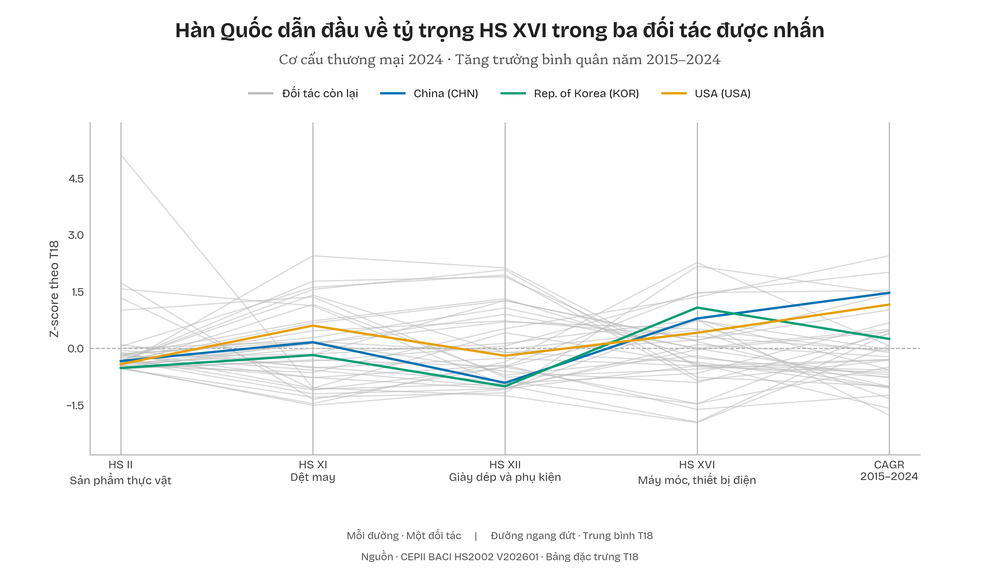

In [3]:
CLEAN = ROOT / "data" / "clean"
OUT = ROOT / "outputs" / "multivariate"
TOP_HS = 4
HIGHLIGHTS = ("CHN", "USA", "KOR")

# Khi nhóm chốt tên file T20 và M6, sửa hai đường dẫn dưới đây.
# Nhãn T20 cần partner_code, cluster_id. Bảng màu M6 cần cluster_id, color (HEX).
T20_LABELS = CLEAN / "partner_clusters.csv"
M6_COLORS = CLEAN / "cluster_colors.csv"

raw, z, axes, ordered, baseline = load_parallel(CLEAN, TOP_HS)
assert set(HIGHLIGHTS).issubset(set(z["partner_iso3"]) & set(PARTNER_COLORS))
assert ordered <= baseline
print(f"{len(z)} đối tác, {len(axes)} trục.")
print("Thứ tự trục:", " → ".join(axis_label(c).split("\n")[0] for c in axes))
print(f"Giao cắt cặp đường ở các trục liền kề: {baseline} theo hạng tỷ trọng, {ordered} sau sắp xếp.")

draft = draw_parallel(z, axes, HIGHLIGHTS)
validate_figure(draft, z, axes)
export_parallel(draft, "C10_parallel", OUT)

cluster = load_clusters(z, T20_LABELS, M6_COLORS)
if cluster is not None:
    result = draw_parallel(z, axes, HIGHLIGHTS, cluster=cluster)
    validate_figure(result, z, axes)
    export_parallel(result, "C10_parallel_clusters", OUT)

## Kết luận

- Thứ tự **HS II → HS XI → HS XII → HS XVI → CAGR** giảm số giao cắt giữa các trục kề nhau từ **1.597 xuống 1.239**, tức **22,4%** so với cách đặt bốn phần theo hạng tỷ trọng bình quân.
- Cả ba đối tác được nhấn đều có tỷ trọng **HS XVI** cao hơn mức bình quân **39,5%** của tập T18. Hàn Quốc cao nhất trong ba nước ở trục này (**63,4%**), tiếp theo là Trung Quốc (**57,6%**) và Hoa Kỳ (**50,0%**).
- Trung Quốc có CAGR cao nhất trong ba đối tác được nhấn, **15,3%/năm**. Hoa Kỳ đạt **13,9%/năm**, Hàn Quốc đạt **9,9%/năm**. Các tỷ trọng và CAGR ở đây mô tả tổng thương mại hai chiều với Việt Nam.

Bản hiện tại là bản nháp trước khi ghép nhãn cụm T20.